<a href="https://colab.research.google.com/github/cpython-projects/da_27_07_2026/blob/main/lesson_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔷 ABC-аналіз

## Навіщо робити ABC-аналіз?

ABC-аналіз — це **простий і потужний спосіб розставити пріоритети**. Він допомагає відповісти на питання:

> Які товари приносять найбільшу частку виручки і де варто зосередити зусилля?

Ми майже завжди стикаємося з тим, що:

* **20% товарів** приносять **80% виручки** (принцип Парето),
* А більшість товарів створюють **мізерну частку доходу**, але потребують ресурсів (зберігання, логістика, маркетинг).

---

## Застосування

* управління запасами (логістика),
* оптимізація асортименту (retail),
* аналіз виручки (фінанси),
* управління SKU (Stock Keeping Unit/товарна позиція) (продуктова аналітика).

---

## Основна ідея

Поділити товари за **внеском у сукупну виручку**:

| Клас | Виручка | Орієнтовний % товарів | Ціль управління           |
| ---- | ------- | --------------------- | -------------------------- |
| A    | 70–80%  | 10–20%                 | Максимальний контроль     |
| B    | 15–25%  | ~30%                   | Пошук покращень           |
| C    | ≤ 5%    | 50–60%                 | Автоматизація, скорочення |

---

## Етапи ABC-аналізу

1. **Підготовка даних**: виручка по кожному товару (або SKU).
2. **Агрегація** (якщо потрібно): групування за ID, сума виручки.
3. **Сортування** за спаданням виручки.
4. **Накопичення** частки від загального обсягу.
5. **Класифікація** за порогами: A / B / C.
6. **Інтерпретація та дії**.

## Приклад

In [1]:
import pandas as pd

data = {
    'item_id': ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A7'],
    'total_sales_value': [1000, 800, 500, 200, 150, 100, 50, 2000]
}

df = pd.DataFrame(data)
df

,item_id,total_sales_value
0,A1,1000
1,A2,800
2,A3,500
3,A4,200
4,A5,150
5,A6,100
6,A7,50
7,A7,2000


Зверніть увагу: `item_id = 'A7'` зустрічається в даних **двічі** (рядки з виручкою `50` і `2000`) — це навмисно, щоб показати, що перед аналізом товар треба згрупувати, інакше одна й та сама позиція "розмажеться" по двох рядках і аналіз буде некоректним.

In [2]:
# Крок 1. Групування за товарами (якщо дублюються)
df_grouped = df.groupby('item_id').agg({
    'total_sales_value': 'sum'
}).reset_index()
df_grouped

,item_id,total_sales_value
0,A1,1000
1,A2,800
2,A3,500
3,A4,200
4,A5,150
5,A6,100
6,A7,2050


In [3]:
# Крок 2. Сортування за спаданням
df_sorted = df_grouped.sort_values('total_sales_value', ascending=False).reset_index(drop=True)
df_sorted

,item_id,total_sales_value
0,A7,2050
1,A1,1000
2,A2,800
3,A3,500
4,A4,200
5,A5,150
6,A6,100


`drop=True` у `reset_index()` важливий: без нього `reset_index()` зберіг би старий (уже не потрібний) порядок індексів як окрему колонку `index`, яка тільки заважала б читати таблицю далі.

In [4]:
# Крок 3. Накопичення та відсоток
df_sorted['cum_total'] = df_sorted['total_sales_value'].cumsum()
df_sorted

,item_id,total_sales_value,cum_total
0,A7,2050,2050
1,A1,1000,3050
2,A2,800,3850
3,A3,500,4350
4,A4,200,4550
5,A5,150,4700
6,A6,100,4800


In [5]:
total = df_sorted.total_sales_value.sum()
df_sorted['cum_total_percents'] = df_sorted.cum_total / total
df_sorted

,item_id,total_sales_value,cum_total,cum_total_percents
0,A7,2050,2050,0.427083
1,A1,1000,3050,0.635417
2,A2,800,3850,0.802083
3,A3,500,4350,0.906250
4,A4,200,4550,0.947917
5,A5,150,4700,0.979167
6,A6,100,4800,1.000000


In [6]:
# Крок 4. Присвоєння класу
def abc_classify(item):
  if item <= 0.8:
    return 'A'
  if item <= 0.95:
    return 'B'
  return 'C'

df_sorted['ABC'] = df_sorted.cum_total_percents.apply(abc_classify)
df_sorted

,item_id,total_sales_value,cum_total,cum_total_percents,ABC
0,A7,2050,2050,0.427083,A
1,A1,1000,3050,0.635417,A
2,A2,800,3850,0.802083,B
3,A3,500,4350,0.906250,B
4,A4,200,4550,0.947917,B
5,A5,150,4700,0.979167,C
6,A6,100,4800,1.000000,C


## Парето-діаграма: класичний спосіб побачити ABC на графіку

ABC-аналіз традиційно малюють як **діаграму Парето**: стовпчики виручки по товару (відсортовані за спаданням) + лінія накопиченого відсотка поверх них, з горизонтальними орієнтирами на 80% і 95% — саме там, де проходять межі класів A/B/C.

> ⚠️ Це один з небагатьох виправданих випадків використати **другу вісь Y** (яку ми вчили уникати): тут обидва ряди — це той самий показник (виручка), тільки одне "як є", а інше "накопичено у відсотках". Це не два різні явища (як виручка і штат), тож ризику натякнути на фальшиву кореляцію немає — навпаки, саме накладання одне на одне й показує, де саме накопичена частка перетинає поріг.

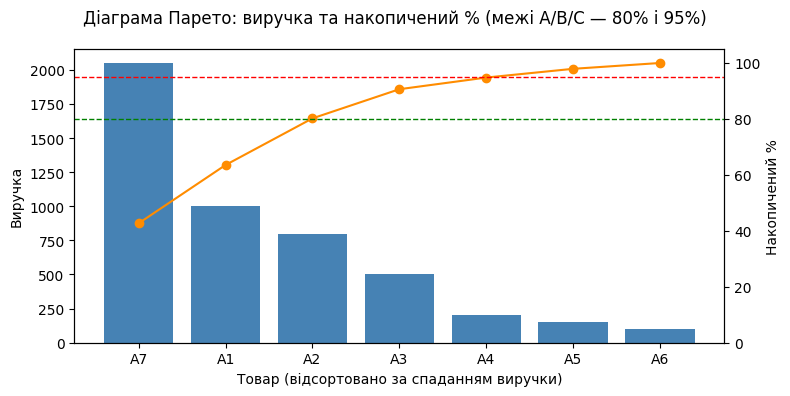

In [7]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.bar(df_sorted['item_id'], df_sorted['total_sales_value'], color='steelblue')
ax1.set_ylabel('Виручка')
ax1.set_xlabel('Товар (відсортовано за спаданням виручки)')

ax2 = ax1.twinx()
ax2.plot(df_sorted['item_id'], df_sorted['cum_total_percents'] * 100, color='darkorange', marker='o')
ax2.axhline(80, color='green', linestyle='--', linewidth=1)
ax2.axhline(95, color='red', linestyle='--', linewidth=1)
ax2.set_ylabel('Накопичений %')
ax2.set_ylim(0, 105)

fig.suptitle('Діаграма Парето: виручка та накопичений % (межі A/B/C — 80% і 95%)')
plt.tight_layout()
plt.show()

На графіку одразу видно те, що в таблиці доводиться вираховувати по рядках: лінія накопиченого відсотка перетинає позначку 80% рівно між `A1` і `A2` — тобто `A7` і `A1` самі по собі вже дають майже дві третини виручки, а решта 5 товарів "добирають" решту.

## ⚠️ Пастка: ABC за виручкою ≠ ABC за прибутком

ABC-аналіз у прикладі вище побудований **за виручкою** — а не за прибутком. Це свідомий і дуже поширений вибір за замовчуванням, але він може вводити в оману: товар з величезним оборотом і мізерною маржею "з'їдає" ресурси класу A, хоча реальної користі бізнесу приносить мало.

In [8]:
data_margin = {
    'item_id': ['P1', 'P2', 'P3', 'P4', 'P5'],
    'revenue': [10000, 8000, 6000, 4000, 2000],
    'margin_pct': [0.05, 0.40, 0.35, 0.10, 0.50],  # частка прибутку в кожній гривні виручки
}
df_margin = pd.DataFrame(data_margin)
df_margin['margin_value'] = df_margin['revenue'] * df_margin['margin_pct']


def abc_by(d, col):
    d = d.sort_values(col, ascending=False).reset_index(drop=True)
    d['cum_pct'] = d[col].cumsum() / d[col].sum()
    d['abc'] = d['cum_pct'].apply(abc_classify)
    return d[['item_id', col, 'cum_pct', 'abc']]


print('ABC за виручкою:')
print(abc_by(df_margin, 'revenue'))
print()
print('ABC за прибутком (margin_value):')
print(abc_by(df_margin, 'margin_value'))

ABC за виручкою:
  item_id  revenue   cum_pct abc
0      P1    10000  0.333333   A
1      P2     8000  0.600000   A
2      P3     6000  0.800000   A
3      P4     4000  0.933333   B
4      P5     2000  1.000000   C

ABC за прибутком (margin_value):
  item_id  margin_value   cum_pct abc
0      P2        3200.0  0.444444   A
1      P3        2100.0  0.736111   A
2      P5        1000.0  0.875000   B
3      P1         500.0  0.944444   B
4      P4         400.0  1.000000   C


**Що змінилось:** `P1` — найбільший за виручкою (33% обороту!) і впевнено клас `A` — але його маржа всього `5%`, тож у грошовому прибутку він дає лише `500` і опускається до класу `B`. А `P5` — навпаки, найменший за виручкою (клас `C`), але з маржею `50%` він піднімається до класу `B` за прибутком. `P2` залишається лідером (`A`) в обох версіях — це той рідкісний товар, який справді і продається багато, і вигідний.

**Висновок:** якщо мета ABC-аналізу — зрозуміти, куди спрямувати маркетинг і закупівлі для максимізації **прибутку** бізнесу (а не просто обороту), рахувати клас варто за `revenue × margin_pct`, а не за самою виручкою. Той самий товар може бути класом `A` за одним критерієм і класом `B` чи `C` за іншим — тому перед аналізом варто явно вирішити й озвучити замовнику, яку саме величину ви класифікуєте.

## Що робити після ABC-класифікації?

### Клас A (ключові)

* Максимум уваги: постачання, склад, просування.
* Стежити за залишками, рекламою, знижками.
* Часто аналізувати динаміку.

### Клас B (середня значущість)

* Оптимізувати: умови закупівлі, постачальників.
* Є потенціал зростання — варто подумати про маркетинг.

### Клас C (низькопріоритетні)

* Мінімізувати запаси.
* Об’єднувати SKU, видаляти неефективні.
* Можливо — перевести на автоматичний контроль.

# 🔷 XYZ-аналіз

## Навіщо робити XYZ-аналіз?

Якщо ABC-аналіз показує, **що важливо за виручкою**, то XYZ-аналіз показує:

> Наскільки **стабільний попит** на товар?

Ви можете мати товар із високою виручкою, але якщо він продається стрибкоподібно і нестабільно — з ним треба поводитися обережно (ризик залишків, дефіциту, списань).

---

## Основна ідея

Оцінити **прогнозованість попиту** за коефіцієнтом варіації.
*Коефіцієнт варіації* — це відносна міра розкиду даних, яка показує, наскільки сильно варіюються значення відносно їхнього середнього.

| Клас | Стабільність попиту     | Інтерпретація                      |
| ---- | ------------------------ | ----------------------------------- |
| X    | Висока стабільність      | Попит майже не змінюється          |
| Y    | Середня прогнозованість  | Є коливання, але в межах норми     |
| Z    | Низька стабільність      | Хаотичний, сезонний або випадковий |

---

## Як вимірюється?

Через **коефіцієнт варіації (CV)**:

$$
\text{CV} = \frac{\text{Стандартне відхилення}}{\text{Середнє значення}}
$$

> ⚠️ Пороги X/Y/Z нижче (`≤0.25` / `≤0.50`) — один з поширених варіантів, саме такий ми візьмемо далі, але це не єдиний стандарт: інша поширена шкала — `X ≤ 10%`, `Y ≤ 25%`, `Z > 25%` (жорсткіша, бо реальний попит рідко буває настільки стабільним). Конкретні пороги завжди варто узгоджувати з тим, наскільки передбачуваний бізнес у принципі.

---

## Етапи XYZ-аналізу

1. Підготовка даних: продажі за періодами (наприклад, за місяцями).
2. Розрахунок середнього та стандартного відхилення по кожному товару.
3. Розрахунок коефіцієнта варіації (CV).
4. Класифікація на X/Y/Z.
5. Інтерпретація та дії.

## ⚠️ Пастка: `cv` по 3-4 точках даних — ненадійна оцінка

У прикладі нижче `cv` рахується всього по **4 місяцях**. Це та сама проблема, що й з довірчими інтервалами: чим менше спостережень, тим менш точна оцінка — і `std`/`cv`, пораховані по жмені точок, можуть сильно "гуляти" від вибірки до вибірки, навіть якщо товар насправді продається стабільно.

Перевіримо це симуляцією: візьмемо товар зі **справжнім** `cv = 0.22` (межово в зоні X) і подивимось, наскільки по-різному виглядатиме оцінений `cv`, якщо рахувати його по 4, 12 чи 24 місяцях.

In [9]:
import numpy as np

rng = np.random.default_rng(7)
true_mean, true_std = 100, 22  # справжній cv = 0.22

for n in [4, 12, 24]:
    cvs = np.array([
        (s := rng.normal(true_mean, true_std, n)).std(ddof=1) / s.mean()
        for _ in range(5000)
    ])
    misclassified = (cvs > 0.25).mean()  # хибно НЕ X, хоча товар насправді X
    print(f'n={n:2} місяців: 90% оцінок cv лежать у ({np.percentile(cvs,5):.2f}, {np.percentile(cvs,95):.2f}), '
          f'помилково класифіковано як "не X" у {misclassified:.0%} випадків')

n= 4 місяців: 90% оцінок cv лежать у (0.08, 0.37), помилково класифіковано як "не X" у 28% випадків
n=12 місяців: 90% оцінок cv лежать у (0.14, 0.30), помилково класифіковано як "не X" у 24% випадків
n=24 місяців: 90% оцінок cv лежать у (0.16, 0.28), помилково класифіковано як "не X" у 17% випадків


**Висновок:** при `n=4` справжній стабільний товар (`cv=0.22`) помилково потрапляє поза клас `X` майже у третині випадків — просто через випадковість того, які саме 4 місяці потрапили у вибірку. При `n=24` ця частка падає в рази. Це не означає, що XYZ по 4 місяцях марний — часто більше даних просто немає (новий товар, сезонний запуск) — але результат варто подавати з застереженням "попередня оцінка, уточнимо по мірі накопичення історії", а не як остаточний вердикт.

## Приклад

In [10]:
data = {
    'item_id': ['A1', 'A2', 'A3', 'A4', 'A5'],
    'jan': [100, 120, 90, 200, 10],
    'feb': [100, 80, 100, 250, 30],
    'mar': [100, 110, 105, 50, 90],
    'apr': [100, 95, 95, 300, 70]
}

df = pd.DataFrame(data)
df

,item_id,jan,feb,mar,apr
0,A1,100,100,100,100
1,A2,120,80,110,95
2,A3,90,100,105,95
3,A4,200,250,50,300
4,A5,10,30,90,70


In [11]:
# Крок 1. Розрахунок середнього та стандартного відхилення за місяцями
df['mean_sales'] = df[['jan', 'feb', 'mar', 'apr']].mean(axis=1)
df['std_sales'] = df[['jan', 'feb', 'mar', 'apr']].std(axis=1)
df

,item_id,jan,feb,mar,apr,mean_sales,std_sales
0,A1,100,100,100,100,100.00,0.000000
1,A2,120,80,110,95,101.25,17.500000
2,A3,90,100,105,95,97.50,6.454972
3,A4,200,250,50,300,200.00,108.012345
4,A5,10,30,90,70,50.00,36.514837


In [12]:
# Крок 2. Коефіцієнт варіації
df['cv'] = (df.std_sales / df.mean_sales)
df

,item_id,jan,feb,mar,apr,mean_sales,std_sales,cv
0,A1,100,100,100,100,100.00,0.000000,0.000000
1,A2,120,80,110,95,101.25,17.500000,0.172840
2,A3,90,100,105,95,97.50,6.454972,0.066205
3,A4,200,250,50,300,200.00,108.012345,0.540062
4,A5,10,30,90,70,50.00,36.514837,0.730297


In [13]:
# Крок 3. Класифікація за порогами
def xyz_classify(item):
  if item <= 0.25:
    return 'X'
  if item <= 0.50:
    return 'Y'
  return 'Z'


df['xyz'] = df.cv.apply(xyz_classify)
df

,item_id,jan,feb,mar,apr,mean_sales,std_sales,cv,xyz
0,A1,100,100,100,100,100.00,0.000000,0.000000,X
1,A2,120,80,110,95,101.25,17.500000,0.172840,X
2,A3,90,100,105,95,97.50,6.454972,0.066205,X
3,A4,200,250,50,300,200.00,108.012345,0.540062,Z
4,A5,10,30,90,70,50.00,36.514837,0.730297,Z


## Як інтерпретувати?

| Клас | Що це означає                               | Що робити?                                           |
| ---- | -------------------------------------------- | ----------------------------------------------------- |
| X    | Попит стабільний, легко прогнозувати         | Планувати точно, тримати у постійній наявності        |
| Y    | Середня прогнозованість, помірні коливання   | Підлаштовуватися під тренди, враховувати сезонність   |
| Z    | Нестабільний, хаотичний попит                | Мінімальні запаси, уникати автоматичного поповнення   |

# 🔷 ABC+XYZ матриця

## Комбінація ABC і XYZ: матриця 3×3

Об’єднуючи обидва аналізи, отримуємо **матрицю з 9 категорій товарів**:

|       | **X (стабільний)** | **Y (помірний)** | **Z (хаотичний)** |
| ----- | ------------------- | ----------------- | ------------------- |
| **A** | AX                  | AY                 | AZ                  |
| **B** | BX                  | BY                 | BZ                  |
| **C** | CX                  | CY                 | CZ                  |

---

## Інтерпретація комірок ABC+XYZ

### 1. **AX — стратегічні товари**

* Висока цінність і стабільний попит.
* Постійна наявність на складі.
* Пріоритетне управління.

---

### 2. **AY — важливі, але з коливаннями**

* Дає великий оборот, але попит нестабільний.
* Потрібен регулярний аналіз попиту та гнучкі закупівлі.

---

### 3. **AZ — важливі, але непередбачувані**

* Високий дохід, але попит хаотичний.
* Ризики переваги/дефіциту.
* Краще закуповувати по факту, за замовленнями.

---

### 4. **BX — середня цінність, стабільний попит**

* Добре прогнозуються.
* Можна закуповувати за планом.
* Рівень контролю трохи нижчий, ніж у AX.

---

### 5. **BY — помірні за значущістю і стабільністю**

* Стандартна стратегія управління запасами.
* Моніторинг, але не пріоритет.

---

### 6. **BZ — середня важливість, хаотичний попит**

* Бажано скоротити склад або перейти на замовлення під клієнта.

---

### 7. **CX — дешеві, але стабільні**

* Можна закуповувати великими партіями.
* Підходять для автоматичного поповнення.

---

### 8. **CY — дешеві, помірно нестабільні**

* Можливо мати запас, але обережно.
* Баланс між витратами та ризиками.

---

### 9. **CZ — дешеві і хаотичні**

* Кандидати на виведення з асортименту.
* Закупівля по факту або виключення.

---

## Як використовувати на практиці?

* **AX, BX** — автоматизація закупівель, регулярний перегляд.
* **AZ, BZ, CZ** — зменшення складських залишків, закупівля по замовленню.
* **CY, CZ** — кандидати на видалення/заміну.
* **ABC** — формує пріоритет за важливістю.
* **XYZ** — формує пріоритет за прогнозованістю.

## Наскрізний приклад: рахуємо ABC і XYZ для одних і тих самих товарів

Вище ABC і XYZ рахувались на **різних** прикладах (7 товарів з однією цифрою виручки — і окремі 5 товарів з продажами по місяцях), тож побачити саму матрицю "в дії" на конкретних SKU ще не було можливості. Нижче — один наскрізний приклад: беремо ті самі 5 товарів з XYZ-аналізу (`jan`-`apr`), рахуємо для них виручку (сума за 4 місяці) і будуємо **обидві** класифікації на одному й тому самому наборі даних.

In [14]:
data = {
    'item_id': ['A1', 'A2', 'A3', 'A4', 'A5'],
    'jan': [100, 120, 90, 200, 10],
    'feb': [100, 80, 100, 250, 30],
    'mar': [100, 110, 105, 50, 90],
    'apr': [100, 95, 95, 300, 70]
}
df = pd.DataFrame(data)
months = ['jan', 'feb', 'mar', 'apr']

# XYZ (та сама логіка, що й вище)
df['mean_sales'] = df[months].mean(axis=1)
df['std_sales'] = df[months].std(axis=1)
df['cv'] = df.std_sales / df.mean_sales
df['xyz'] = df.cv.apply(xyz_classify)

# ABC: виручка товару — це сума продажів за всі місяці
df['total_sales_value'] = df[months].sum(axis=1)

df_combined = df.sort_values('total_sales_value', ascending=False).reset_index(drop=True)
total = df_combined['total_sales_value'].sum()
df_combined['cum_total_percents'] = df_combined['total_sales_value'].cumsum() / total
df_combined['abc'] = df_combined['cum_total_percents'].apply(abc_classify)

# Об'єднуємо в одну категорію матриці
df_combined['abc_xyz'] = df_combined['abc'] + df_combined['xyz']

df_combined[['item_id', 'total_sales_value', 'cum_total_percents', 'abc', 'cv', 'xyz', 'abc_xyz']]

,item_id,total_sales_value,cum_total_percents,abc,cv,xyz,abc_xyz
0,A4,800,0.364465,A,0.540062,Z,AZ
1,A2,405,0.548975,A,0.172840,X,AX
2,A1,400,0.731207,A,0.000000,X,AX
3,A3,390,0.908884,B,0.066205,X,BX
4,A5,200,1.000000,C,0.730297,Z,CZ


In [15]:
# Скільки товарів потрапило в кожну клітинку матриці 3х3
matrix_counts = pd.crosstab(df_combined['abc'], df_combined['xyz'])
matrix_counts

xyz,X,Z
abc,,
A,2,1
B,1,0
C,0,1


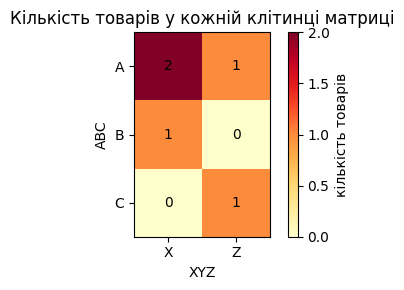

In [16]:
# Та сама матриця — наочніше, як теплова карта
fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(matrix_counts.values, cmap='YlOrRd')

ax.set_xticks(range(len(matrix_counts.columns)))
ax.set_xticklabels(matrix_counts.columns)
ax.set_yticks(range(len(matrix_counts.index)))
ax.set_yticklabels(matrix_counts.index)
ax.set_xlabel('XYZ')
ax.set_ylabel('ABC')

for i in range(matrix_counts.shape[0]):
    for j in range(matrix_counts.shape[1]):
        ax.text(j, i, matrix_counts.values[i, j], ha='center', va='center')

ax.set_title('Кількість товарів у кожній клітинці матриці')
plt.colorbar(im, label='кількість товарів')
plt.tight_layout()
plt.show()

**Що показав цей наскрізний приклад:** `A1`, `A2` і `A4` всі потрапляють у клас `A` за виручкою (разом дають 73% обороту), але це дуже різні товари з точки зору ризику:

* `A1` і `A2` — клас **AX**: висока виручка **і** стабільний попит (`cv` близько 0) — саме ті "золоті" товари, які варто тримати в постійній наявності без зайвих роздумів.
* `A4` — клас **AZ**: та сама висока виручка, але `cv ≈ 0.54` — хаотичний, непередбачуваний попит. Якби дивитись тільки на ABC (виручку), `A4` виглядав би так само надійно, як `A1`/`A2` — і це якраз та помилка, яку комбінована матриця дозволяє не зробити: однаковий клас A за грошима ще не означає однакову стратегію закупівлі.
* `A5` — єдиний товар у класі **CZ**: і найменша виручка, і найхаотичніший попит — прямий кандидат на виведення з асортименту або закупівлю лише під конкретне замовлення.

# 🔷 Деталізовані дії по кожній клітинці матриці

### ✅ A/X — **Золотий фонд**

* Високий внесок у виручку
* Стабільний попит
* **Що робити:**

  * Тримати максимальний пріоритет
  * Гарантувати постійну доступність
  * Ретельно відстежувати продажі
  * Не допускати out-of-stock за жодних умов
  * Застосовувати автоматичне поповнення

---

### ✅ A/Y — **Важливі, але коливаються**

* Висока цінність
* Середня стабільність
* **Що робити:**

  * Відстежувати тренди та сезонність
  * Використовувати просунутий прогноз попиту (наприклад, ковзні середні)
  * Тримати середній рівень запасів
  * Планувати промо, якщо спадання повторюється по часу

---

### ✅ A/Z — **Ризикові, але дорогі**

* Дуже важливі
* Дуже нестабільні
* **Що робити:**

  * Перевірити причини нестабільності: акції, збої постачання, сезонність
  * Застосувати підхід JIT (just in time)
  * Уникати переваги запасів
  * Узгодити зі стратегічним відділом: «тримати під замовлення» або «пульсова закупівля»

---

### 🟨 B/X — **Надійні робочі конячки**

* Середня цінність
* Надійний попит
* **Що робити:**

  * Підтримувати запаси стабільно
  * Можна автоматизувати закупівлі
  * Контролювати залишки, але без надмірностей

---

### 🟨 B/Y — **Менш стабільні, середня цінність**

* Складніше прогнозувати
* **Що робити:**

  * Використовувати помірне буферне зберігання
  * Відстежувати сплески
  * Застосовувати ручний контроль або ML-модель на основі коливань

---

### 🟨 B/Z — **Нестабільні та середньоцінні**

* Погано прогнозуються
* **Що робити:**

  * Мінімізувати запаси
  * Під замовлення, по заявці
  * Не тримати на складі «про запас»

---

### 🟥 C/X — **Багато, стабільно, але дешево**

* Мало приносять, але добре прогнозуються
* **Що робити:**

  * Використовувати автоматичне поповнення за залишковим принципом
  * Продавати через long-tail канали (маркетплейси, акції, розпродажі)
  * Можна формувати промо-набори

---

### 🟥 C/Y — **Багато, середньо передбачувано**

* Неефективні та нестабільні
* **Що робити:**

  * Провести аналіз — навіщо вони потрібні?
  * Скоротити номенклатуру
  * Передати на знижену ціну або розпродаж

---

### 🟥 C/Z — **Нижній баласт**

* Мінімальний внесок + хаотичний попит
* **Що робити:**

  * Оптимізувати: прибрати з зберігання
  * Списати, ліквідувати
  * Перевести на дозаказ за запитом клієнта
  * Не тримати на складі